In [267]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [268]:
customers = pd.read_csv(r"D:\ML Projects\Suprvised practice\Data set\customer_ml_practice.csv")
customers.head(5)
customers.shape

(300, 13)

In [177]:
customers.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
customer_id,300.0,1150.500000,86.746758,1001.0,1075.75,1150.50,1225.25,1300.0
age,300.0,41.326667,13.887506,18.0,29.00,42.00,53.00,65.0
tenure_months,300.0,36.660000,20.295915,1.0,19.00,36.00,55.00,72.0
monthly_income,300.0,64322.713333,28664.046938,18055.0,39660.75,63275.50,89899.00,119570.0
monthly_spend,300.0,4713.983333,2214.426170,522.0,2988.75,4805.00,6627.75,8482.0
support_calls,300.0,2.156667,1.514298,0.0,1.00,2.00,3.00,8.0
login_frequency,300.0,18.033333,6.071940,2.0,14.00,17.00,22.00,33.0
satisfaction,300.0,6.664667,1.787962,1.2,5.50,6.75,7.80,10.0
next_month_spend,300.0,7133.893333,2405.997544,1402.0,5272.00,7334.50,8980.50,11585.0


In [178]:
customers.isnull().sum()
customers.isna().sum()

customer_id         0
age                 0
tenure_months       0
monthly_income      0
monthly_spend       0
support_calls       0
login_frequency     0
contract            0
payment_method      0
has_discount        0
satisfaction        0
churn               0
next_month_spend    0
dtype: int64

In [179]:
customers.duplicated().sum()
customers[customers.duplicated()]

,customer_id,age,tenure_months,monthly_income,monthly_spend,support_calls,login_frequency,contract,payment_method,has_discount,satisfaction,churn,next_month_spend


In [269]:
customers.select_dtypes(include='str').nunique()

contract          3
payment_method    4
has_discount      2
churn             2
dtype: int64

In [181]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       300 non-null    int64  
 1   age               300 non-null    int64  
 2   tenure_months     300 non-null    int64  
 3   monthly_income    300 non-null    int64  
 4   monthly_spend     300 non-null    float64
 5   support_calls     300 non-null    int64  
 6   login_frequency   300 non-null    float64
 7   contract          300 non-null    str    
 8   payment_method    300 non-null    str    
 9   has_discount      300 non-null    str    
 10  satisfaction      300 non-null    float64
 11  churn             300 non-null    str    
 12  next_month_spend  300 non-null    float64
dtypes: float64(4), int64(5), str(4)
memory usage: 30.6 KB


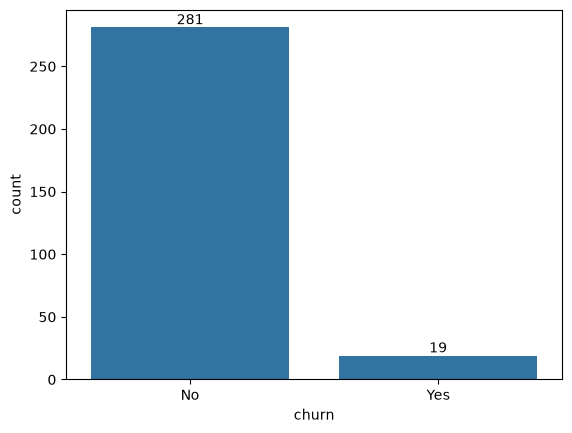

In [270]:
#churn distribution
ax = sns.countplot(x='churn',data=customers)
ax.bar_label(ax.containers[0])      # to show labels of bar
plt.show()

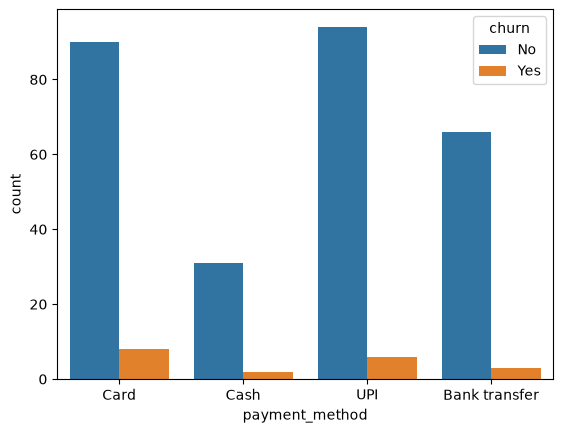

In [183]:
#Payment method dstribution
sns.countplot(x='payment_method',data=customers,hue='churn')
plt.show()

In [184]:
customers['payment_method'].value_counts()

payment_method
UPI              100
Card              98
Bank transfer     69
Cash              33
Name: count, dtype: int64

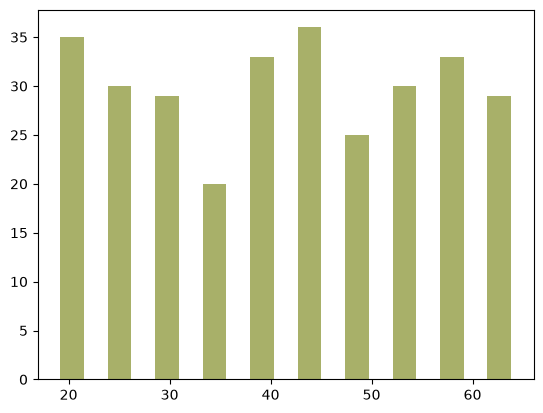

In [185]:
plt.hist(customers.age,bins=10,color="#A8B069",rwidth=0.5)
plt.show()

<Axes: xlabel='monthly_spend'>

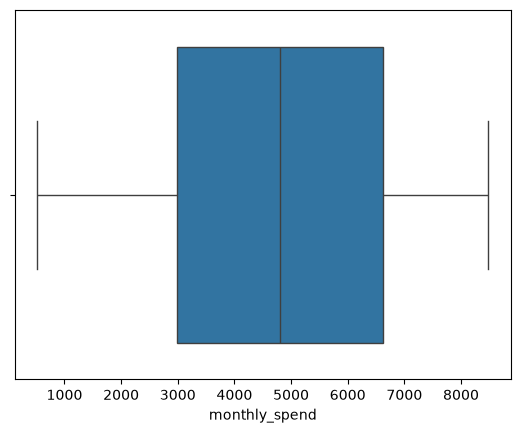

In [186]:
sns.boxplot(x='monthly_spend',data=customers)

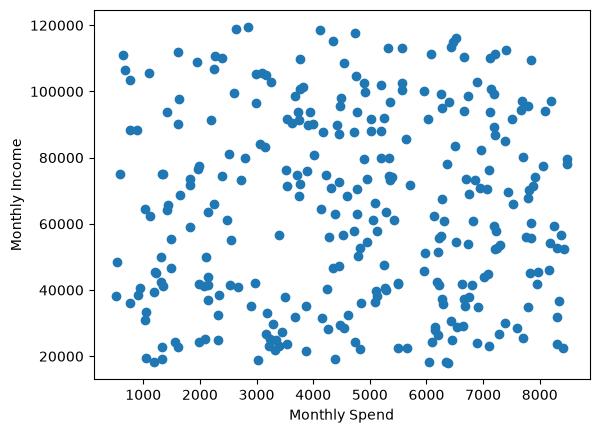

In [187]:
plt.scatter(x="monthly_spend",y="monthly_income",data=customers)
plt.xlabel("Monthly Spend")
plt.ylabel("Monthly Income")
plt.show()

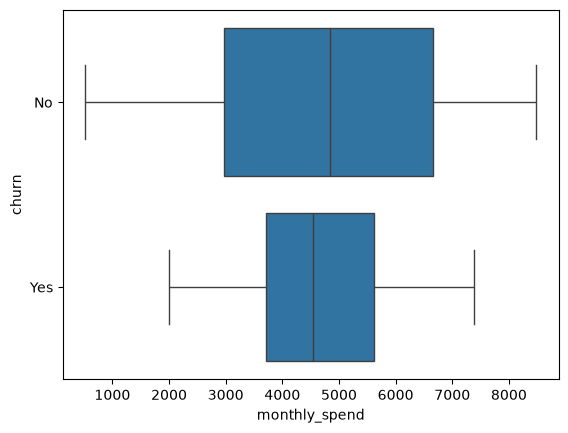

In [188]:
sns.boxplot(x='monthly_spend',y='churn',data=customers)
plt.show()

#**Here i can see customers who spent less has more chances to get churned**

In [189]:
customers.columns

Index(['customer_id', 'age', 'tenure_months', 'monthly_income',
       'monthly_spend', 'support_calls', 'login_frequency', 'contract',
       'payment_method', 'has_discount', 'satisfaction', 'churn',
       'next_month_spend'],
      dtype='str')

In [271]:
customers_str = customers.select_dtypes(include='str')
customers_str
x_copy = customers.copy()

In [272]:
x = x_copy.drop(columns=['customer_id','churn','next_month_spend'])

y = x_copy['next_month_spend']

In [273]:
from sklearn.preprocessing import OneHotEncoder

x = pd.get_dummies(x,drop_first=True,dtype=int)

x

,age,tenure_months,monthly_income,monthly_spend,support_calls,login_frequency,satisfaction,contract_One year,contract_Two year,payment_method_Card,payment_method_Cash,payment_method_UPI,has_discount_Yes
0,56,66,40700,945.0,2,20.0,9.3,0,0,1,0,0,1
1,46,54,52620,7239.0,2,13.0,5.5,1,0,0,1,0,1
2,32,35,38559,913.0,3,16.0,8.5,0,1,0,0,1,0
3,60,61,111045,646.0,2,11.0,9.8,1,0,1,0,0,0
4,25,41,111396,6076.0,2,24.0,6.0,0,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,52,6,45139,7824.0,4,14.0,9.5,0,1,0,0,1,0
296,42,58,95149,6272.0,5,20.0,8.2,1,0,0,0,0,0
297,46,44,74138,5383.0,6,23.0,6.6,0,1,0,0,0,1
298,35,45,94125,8094.0,1,23.0,9.6,0,1,1,0,0,0


In [274]:
from sklearn.model_selection import train_test_split
# Here i'm using startify=y, as i want equal distribution of data in x and y
# But in linearly seperable data it is not required
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [275]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


In [276]:
from sklearn.linear_model import LinearRegression,Lasso,Ridge,LogisticRegression
from sklearn.metrics import r2_score,root_mean_squared_error,mean_absolute_error,mean_squared_error

lr = LinearRegression()
lr.fit(x_train,y_train)
lr.score(x_test,y_test)
y_pred = lr.predict(x_test)

r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

# Print results
print("R² Score:", r2)
print("MSE:", mse)
print("MAE:", mae)
print("RMSE:", rmse)

# Model score
print("Model Score:", lr.score(x_test, y_test))


R² Score: 0.9683740897171822
MSE: 156688.5751091472
MAE: 329.0382628705081
RMSE: 395.8390772891772
Model Score: 0.9683740897171822


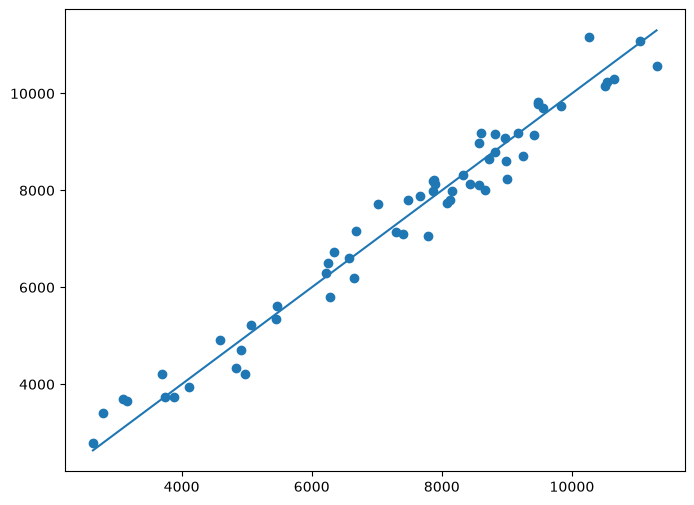

In [196]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)
plt.show()

In [277]:
# Decision Tree
from sklearn.tree import DecisionTreeRegressor
criterion = ['squared_error', 'absolute_error', 'poisson']
#score = []
for x in criterion:
    dt = DecisionTreeRegressor(criterion=x)
    dt.fit(x_train,y_train)
    score = dt.score(x_test,y_test)
    print(f"criterion: {x} score:{score}" )
    
## Here, poisson criterion gives the highest R² score

criterion: squared_error score:0.8822749786147407
criterion: absolute_error score:0.8893091820507096
criterion: poisson score:0.8894727324249747


In [278]:
from sklearn.model_selection import cross_val_score,KFold
from sklearn.ensemble import RandomForestRegressor
kf = KFold(n_splits=5,shuffle=True,random_state=42)

models = {
    "LinearRegression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "Decision_Tree":DecisionTreeRegressor(random_state=42),
    "Random_Forest":RandomForestRegressor(random_state=42)
          }

#cv1 = cross_val_score(LinearRegression(),x_train,y_train,cv=kf)

for name,model in models.items():
    cv = cross_val_score(model,x_train,y_train,cv=kf,scoring='r2')
    print(f"Model: {name} score:{cv.mean()}")


# Lasso gives the highest mean CV R² among these models.
# I will tune Lasso's alpha using GridSearchCV.

Model: LinearRegression score:0.978343689045038
Model: Lasso score:0.9783811948297123
Model: Ridge score:0.9747287003159292
Model: Decision_Tree score:0.9077273425176934
Model: Random_Forest score:0.9508751025537153


In [ ]:
from sklearn.model_selection import GridSearchCV

#Here parameters always should be dictionary format
param = {'alpha':[0.01,0.1,1,10,100]}

model = Lasso()

grid = GridSearchCV(model,param,cv=kf,scoring='r2')

grid.fit(x_train, y_train)

print("Best parameter:", grid.best_params_)
print("Best CV score:", grid.best_score_)

#best-performing model instance found during the hyperparameter search
best_lasso = grid.best_estimator_

y_pred = best_lasso.predict(x_test)

print("Test R²:", r2_score(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

Best parameter: {'alpha': 1}
Best CV score: 0.9783811948297123
Test R²: 0.968258375389917
Test MAE: 330.12325456784686
Test MSE: 157261.87443545152
Test RMSE: 396.56257316525915


In [ ]:
# For practice purpose i'm calculating 
model1 = RandomForestRegressor()
param1 = {"n_estimators":[50,100,150,200],
          "max_depth":[3,4,5,6]}
grid1 = GridSearchCV(model1,param1,cv=kf,scoring='r2')

grid1.fit(x_train,y_train)

print("Best Parameter",grid1.best_params_)
print("Best Score",grid1.best_score_)

#best-performing model instance found during the hyperparameter search
best_rf = grid1.best_estimator_

y_pred_rf = best_rf.predict(x_test)

print("Test R²:", r2_score(y_test, y_pred_rf))
print("Test MAE:", mean_absolute_error(y_test, y_pred_rf))
print("Test MSE:", mean_squared_error(y_test, y_pred_rf))
print("Test RMSE:", root_mean_squared_error(y_test, y_pred_rf))

Best Parameter {'max_depth': 6, 'n_estimators': 50}
Best Score 0.95092563677049
Test R²: 0.9367541567741431
Test MAE: 461.1796575527961
Test MSE: 313347.5358658694
Test RMSE: 559.7745402087071


In [ ]:
results = pd.DataFrame({"Model":["Linear Regression","Lasso","Random Forest"],
                        "R² Score":[0.9699,0.9695,0.9408],
                        "MAE": [318.623,321.952,452.197],
                        "RMSE":[386.139,388.599,541.178]})
results

# Here Linear regression model should be good choice as R² is maximum and MAE i.e distance is less as compare to other models

,Model,R² Score,MAE,RMSE
0,Linear Regression,0.9699,318.623,386.139
1,Lasso,0.9695,321.952,388.599
2,Random Forest,0.9408,452.197,541.178


In [ ]:
customers_classi = customers.copy()

In [295]:
x = customers_classi.drop(columns=['customer_id','churn','next_month_spend'])

y = customers_classi['churn']

In [296]:
x_train,x_test,y_train,y_test = train_test_split(x,y,stratify=y,test_size=0.2,random_state=42)
# Using stratify=y distributing data in equal proportion (eg. train -> 9:2, test -> 9:2)

In [298]:
cat_col_x_train = x_train.select_dtypes(include='str')
cat_col_x_test = x_test.select_dtypes(include='str')
print(cat_col_x_train.head(5))
num_col_x_train = x_train.select_dtypes(exclude='str')
num_col_x_test = x_test.select_dtypes(exclude="str")

           contract payment_method has_discount
139  Month-to-month           Card           No
121  Month-to-month  Bank transfer          Yes
292        Two year            UPI           No
181        Two year           Cash           No
64   Month-to-month           Card          Yes


In [323]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop='first',sparse_output=False,handle_unknown='ignore')

encoded_x_train = ohe.fit_transform(cat_col_x_train)
encoded_pd_x_train = pd.DataFrame(encoded_x_train,
                                  columns=ohe.get_feature_names_out(cat_col_x_train.columns),
                                  index=cat_col_x_train.index)

encoded_pd_x_train.head(5)

encoded_x_test = ohe.transform(cat_col_x_test)
encoded_pd_x_test = pd.DataFrame(encoded_x_test,
                                 columns=ohe.get_feature_names_out(cat_col_x_test.columns),
                                 index=cat_col_x_test.index)

encoded_pd_x_test.head(5)

,contract_One year,contract_Two year,payment_method_Card,payment_method_Cash,payment_method_UPI,has_discount_Yes
135,0.0,0.0,0.0,0.0,1.0,0.0
7,0.0,1.0,0.0,0.0,0.0,1.0
199,1.0,0.0,1.0,0.0,0.0,0.0
299,0.0,0.0,1.0,0.0,0.0,1.0
112,0.0,0.0,0.0,0.0,1.0,0.0


In [315]:
processed_x_train = pd.concat([num_col_x_train,encoded_pd_x_train],axis=1)

processed_x_test = pd.concat([num_col_x_test,encoded_pd_x_test],axis=1)

In [ ]:
print("Before balancing data")
print(y_train.value_counts())
#here i can see data is higly imbalanced

#To balance 
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
rosx, rosy = ros.fit_resample(processed_x_train,y_train)

print("\n After balancing data")
print(rosy.value_counts())

Before balancing data
churn
No     225
Yes     15
Name: count, dtype: int64

 After balancing data
churn
No     225
Yes    225
Name: count, dtype: int64


In [313]:
print(rosx.head(3))

   age  tenure_months  monthly_income  monthly_spend  support_calls  \
0   31             63          110234         2387.0              1   
1   40             17          112074         1613.0              2   
2   52             56           19605         1046.0              3   

   login_frequency  satisfaction  contract_One year  contract_Two year  \
0             10.0           3.8                0.0                0.0   
1             30.0          10.0                0.0                0.0   
2             18.0           6.0                0.0                1.0   

   payment_method_Card  payment_method_Cash  payment_method_UPI  \
0                  1.0                  0.0                 0.0   
1                  0.0                  0.0                 0.0   
2                  0.0                  0.0                 1.0   

   has_discount_Yes  
0               0.0  
1               1.0  
2               0.0  


In [ ]:
scaling = MinMaxScaler(feature_range=(0,1))

# Transforming train and test separately to avoid data leakage
scaled_x_train = scaling.fit_transform(rosx)   #Use balanced x_train

scaled_x_test = scaling.transform(processed_x_test) # Use encoded data

In [334]:
logi = LogisticRegression()  # here only support l2
logi.fit(scaled_x_train,rosy)
logi.score(scaled_x_test,y_test)
y_pred = logi.predict(scaled_x_test)



In [356]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred,pos_label='Yes') #Here churn(output) column is in yes/no format
recall = recall_score(y_test,y_pred,pos_label='Yes') #Here churn(output) column is in yes/no format
f1 = f1_score(y_test,y_pred,pos_label='Yes') #Here churn(output) column is in yes/no format


In [358]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score

estimators = [50, 100, 150, 200]
score = []

for i in estimators:

    rfc = RandomForestClassifier(
        n_estimators=i,
        random_state=42
    )

    rfc.fit(rosx, rosy)

    y_pred_rf = rfc.predict(processed_x_test)

    accuracy = accuracy_score(y_test, y_pred_rf)
    precision = precision_score(
        y_test, y_pred_rf, pos_label='Yes'
    )
    recall = recall_score(
        y_test, y_pred_rf, pos_label='Yes'
    )
    f1 = f1_score(
        y_test, y_pred_rf, pos_label='Yes'
    )

    score.append(accuracy)

    print(
        f"n_estimators = {i}\n"
        f"Accuracy  = {accuracy:.4f}\n"
        f"Precision = {precision:.4f}\n"
        f"Recall    = {recall:.4f}\n"
        f"F1 Score  = {f1:.4f}\n"
    )


n_estimators = 50
Accuracy  = 0.9167
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000

n_estimators = 100
Accuracy  = 0.9333
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000



c:\Users\Hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


n_estimators = 150
Accuracy  = 0.9333
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000

n_estimators = 200
Accuracy  = 0.9333
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000



c:\Users\Hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [362]:
from sklearn.ensemble import GradientBoostingClassifier

estimators_gb = [50, 100, 150, 200]
score =[]

for i in estimators_gb:

    gb = GradientBoostingClassifier(
        n_estimators=i,
        random_state=42
    )

    gb.fit(rosx, rosy)

    y_pred_gb = gb.predict(processed_x_test)

    accuracy = accuracy_score(y_test, y_pred_gb)
    precision = precision_score(
        y_test, y_pred_gb, pos_label='Yes'
    )
    recall = recall_score(
        y_test, y_pred_gb, pos_label='Yes'
    )
    f1 = f1_score(
        y_test, y_pred_gb, pos_label='Yes'
    )

    score.append(accuracy)

    print(
        f"n_estimators = {i}\n"
        f"Accuracy  = {accuracy:.4f}\n"
        f"Precision = {precision:.4f}\n"
        f"Recall    = {recall:.4f}\n"
        f"F1 Score  = {f1:.4f}\n"
    )

n_estimators = 50
Accuracy  = 0.8500
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000

n_estimators = 100
Accuracy  = 0.8833
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000

n_estimators = 150
Accuracy  = 0.9000
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000

n_estimators = 200
Accuracy  = 0.9000
Precision = 0.0000
Recall    = 0.0000
F1 Score  = 0.0000



In [369]:
# Score of random forest is high also f1 and recall score of gradient boosting is same 
# so i'm going to tune paramters of random forest

from sklearn.model_selection import GridSearchCV
model_class = RandomForestClassifier()
para_class = {'n_estimators':[50,100,150,200],
              'criterion':['gini', 'entropy', 'log_loss'],
              }
grid_class = GridSearchCV(model_class,para_class)

grid_class.fit(rosx,rosy)



Best Score:  0.9977777777777778
Best Parameters:  {'criterion': 'gini', 'n_estimators': 100}


In [371]:
print("Best Score: ",grid_class.best_score_)
print("Best Parameters: ",grid_class.best_params_)

##best-performing model instance found during the hyperparameter search
grid_class.best_estimator_

Best Score:  0.9977777777777778
Best Parameters:  {'criterion': 'gini', 'n_estimators': 100}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric